In [ ]:
from google.colab import drive
import pandas as pd

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
path = '/content/drive/MyDrive/Data_Assignment/'

In [ ]:
customers = pd.read_csv(f'{path}customers.csv')
products = pd.read_csv(f'{path}products.csv')
transactions = pd.read_csv(f'{path}transactions.csv')
print("files loaded successfully")

files loaded successfully


In [ ]:
#dataset size and structure
print("Dataset sizes")
print(f"customers: {customers.shape}")
print(f"products: {products.shape}")
print(f"transactions: {transactions.shape}")

Dataset sizes
customers: (5000, 13)
products: (200, 13)
transactions: (23814, 12)


In [ ]:
#key columns
print("Key columns")
print("Customers:", customers.columns.tolist())
print("Products:", products.columns.tolist())
print("Transactions:", transactions.columns.tolist())

Key columns
Customers: ['customer_id', 'registration_date', 'email', 'first_name', 'last_name', 'age', 'gender', 'city', 'province', 'country', 'postal_code', 'customer_segment', 'marketing_consent']
Products: ['product_id', 'product_name', 'category', 'subcategory', 'brand', 'current_price', 'cost_price', 'stock_quantity', 'weight_kg', 'launch_date', 'is_active', 'rating', 'review_count']
Transactions: ['transaction_id', 'customer_id', 'transaction_date', 'product_id', 'quantity', 'unit_price', 'total_amount', 'discount_amount', 'payment_method', 'shipping_cost', 'order_status', 'channel']


In [ ]:
print("customers")
print(customers.info())
print(customers.isnull().sum())

customers
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        5000 non-null   object 
 1   registration_date  5000 non-null   object 
 2   email              4900 non-null   object 
 3   first_name         5000 non-null   object 
 4   last_name          5000 non-null   object 
 5   age                4950 non-null   float64
 6   gender             5000 non-null   object 
 7   city               5000 non-null   object 
 8   province           5000 non-null   object 
 9   country            5000 non-null   object 
 10  postal_code        5000 non-null   object 
 11  customer_segment   5000 non-null   object 
 12  marketing_consent  5000 non-null   bool   
dtypes: bool(1), float64(1), object(11)
memory usage: 473.8+ KB
None
customer_id            0
registration_date      0
email                100
first_name         

In [ ]:
print("products summary")
products.info()
print(products.isnull().sum())

products summary
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      200 non-null    object 
 1   product_name    200 non-null    object 
 2   category        200 non-null    object 
 3   subcategory     200 non-null    object 
 4   brand           200 non-null    object 
 5   current_price   200 non-null    float64
 6   cost_price      200 non-null    float64
 7   stock_quantity  200 non-null    int64  
 8   weight_kg       200 non-null    float64
 9   launch_date     200 non-null    object 
 10  is_active       200 non-null    bool   
 11  rating          190 non-null    float64
 12  review_count    200 non-null    int64  
dtypes: bool(1), float64(4), int64(2), object(6)
memory usage: 19.1+ KB
product_id         0
product_name       0
category           0
subcategory        0
brand              0
current_price      0
cost_

In [ ]:
print("Transactions Summary")
transactions.info()
print(transactions.isnull().sum())

Transactions Summary
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23814 entries, 0 to 23813
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    23814 non-null  object 
 1   customer_id       23814 non-null  object 
 2   transaction_date  23814 non-null  object 
 3   product_id        23814 non-null  object 
 4   quantity          23814 non-null  int64  
 5   unit_price        23814 non-null  float64
 6   total_amount      23814 non-null  float64
 7   discount_amount   23814 non-null  float64
 8   payment_method    23814 non-null  object 
 9   shipping_cost     23814 non-null  float64
 10  order_status      23814 non-null  object 
 11  channel           23814 non-null  object 
dtypes: float64(4), int64(1), object(7)
memory usage: 2.2+ MB
transaction_id      0
customer_id         0
transaction_date    0
product_id          0
quantity            0
unit_price          0
total_amount      

In [ ]:
#handle missing values
customers['age'] = customers['age'].fillna(customers['age'].median())
customers['email'] = customers['email'].fillna('Unknown')
products['rating'] = products['rating'].fillna(0)

In [ ]:
#Ensure appropriate date types
customers['registration_date'] = pd.to_datetime (customers['registration_date'])
products['launch_date'] = pd.to_datetime (products['launch_date'])
transactions['transaction_date'] = pd.to_datetime (transactions['transaction_date'])

In [ ]:
#join dataset
df_enriched_sales = transactions.merge(products, on='product_id', how='left')


In [ ]:
#create derived features
customer_metrics = transactions.groupby('customer_id').agg(total_spend=('total_amount', 'sum'),order_count=('transaction_id', 'count'),last_purchase_date=('transaction_date', 'max')).reset_index()
customer_metrics['avg_order_value'] = customer_metrics['total_spend'] / customer_metrics['order_count']
latest_date = transactions['transaction_date'].max()
customer_metrics['days_since_last_purchase'] = (latest_date - customer_metrics['last_purchase_date']).dt.days
customers_final = customers.merge(customer_metrics, on='customer_id', how='left')

customers_final[['total_spend','order_count','avg_order_value']] = customers_final[['total_spend','order_count','avg_order_value']].fillna(0)

print("successfull")
display(customers_final[['customer_id', 'total_spend', 'order_count', 'avg_order_value', 'days_since_last_purchase']].head())

successfull


,customer_id,total_spend,order_count,avg_order_value,days_since_last_purchase
0,CUST000000,1200.20,4.0,300.050000,100.0
1,CUST000001,0.00,0.0,0.000000,NaN
2,CUST000002,257.16,3.0,85.720000,87.0
3,CUST000003,835.86,4.0,208.965000,129.0
4,CUST000004,2465.33,12.0,205.444167,37.0


Data Quality issues: I identified 50 missing values in the age column and 10 missing email entries in the customer dataset, and 10 missing ratings in products datasets.

Data types: all date columns were loaded as strings, which prevented time based calculations.


Inactivity: several customers had no transaction history, resulting in null values after merging tables.

How I addressed issues: missing ages were
filled with median to avoid outlier bias which means preventing extreme value that is much higher or lower than the rest of the group.

missing emails were labeled as unknown, and missing ratings set to 0.

used pd.to_datetime() to convert dates, for calculation of days since last purchase.

handled non-purchasers by filling their spend and order counts with 0.

In [ ]:
#part 2 , Rule Based approach
spend_threshold = customers_final[customers_final['total_spend'] > 0]['total_spend'].quantile(0.75)
order_threshold = customers_final[customers_final['order_count'] > 0]['order_count'].quantile(0.75)

def segment_customer(row):
    #never purchased(NAN)
    if row['total_spend'] == 0:
        return 'inactive/New'
    #high value loyal
    if row['total_spend'] > spend_threshold and row['order_count'] >= order_threshold:
        return 'high-value loyal'

    #purchased before but not in the last 6 months
    if not pd.isna(row['days_since_last_purchase']) and row['days_since_last_purchase'] > 180:
        return 'At Risk'

    #regular cutomer
    return 'Regular customer'

customers_final['segment'] = customers_final.apply(segment_customer, axis=1)
print(f"segmentation thresholds: Spend >= ${spend_threshold:.2f}, Orders >= {order_threshold}")


segmentation thresholds: Spend >= $1691.73, Orders >= 7.0


In [ ]:
from numpy import average
segment_summary = customers_final.groupby('segment').agg(
    number_of_customers=('customer_id', 'count'),
    average_spend=('total_spend', 'mean'),
    average_orders=('order_count', 'mean'),
).reset_index().round(2)

print("cutomer segment summary")
display(segment_summary)

cutomer segment summary


,segment,number_of_customers,average_spend,average_orders
0,At Risk,1484,508.67,2.07
1,Regular customer,1389,825.43,3.60
2,high-value loyal,816,4749.45,19.30
3,inactive/New,1311,0.00,0.00


High Vlaue Loyal segment has highest avrg ordervalue which means they are the most profitable.
At Risk segment is large, suggest that we are losing customers after thier few purchases.
Inactive customers may require a welcome promotion.

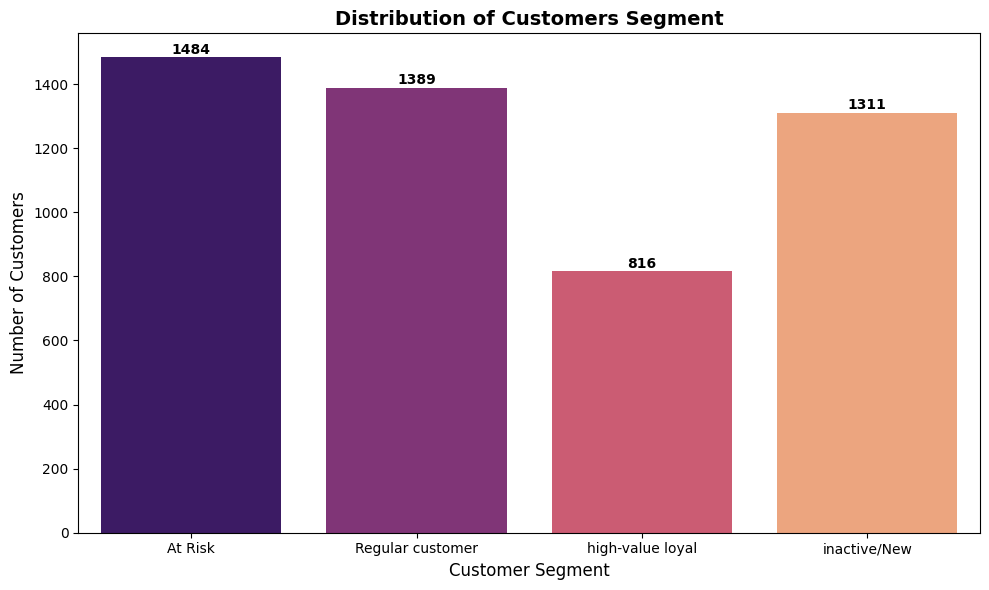

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(data=segment_summary, x='segment', y='number_of_customers', hue='segment',legend=False, palette='magma')

plt.title('Distribution of Customers Segment',fontsize=14, fontweight='bold')
plt.xlabel('Customer Segment' , fontsize=12)
plt.ylabel('Number of Customers' , fontsize=12)

#add labels on top of the bars
for i, val in enumerate(segment_summary['number_of_customers']):
    plt.text(i, val + 1, str(int(val)), ha='center', va='bottom' , fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
customers_final.to_csv('customers_final.csv', index=False)
print("file saved: customers_final.csv")

file saved: customers_final.csv


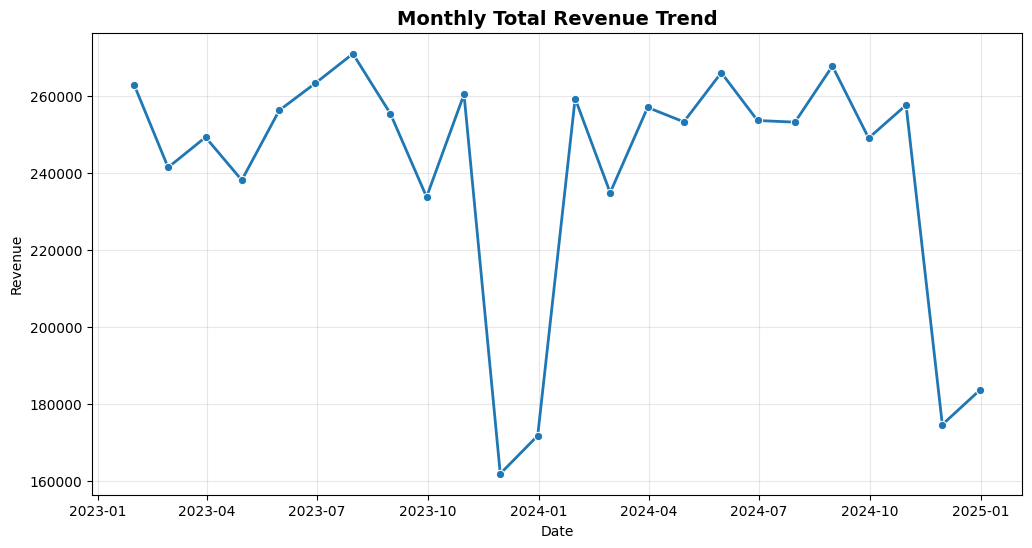

In [ ]:
#Part 3

#resample data by month , ME-month end, MS - month start
sales_trend= transactions.set_index('transaction_date').resample('ME').agg({'total_amount':'sum','transaction_id':'nunique'}).reset_index()

#calculate monthly AOV
sales_trend['avg_order_value'] = sales_trend['total_amount'] / sales_trend['transaction_id']

#visualization of reveue trend
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.lineplot(data=sales_trend, x='transaction_date', y='total_amount',marker='o', color='tab:blue', linewidth=2)
plt.title('Monthly Total Revenue Trend',fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.grid(True, alpha=0.3)
plt.show()




In [ ]:
#display table
sales_trend_display = sales_trend.copy()
sales_trend_display['transaction_date'] = sales_trend_display['transaction_date'].dt.strftime('%B %Y')
display(sales_trend_display.round(2))

,transaction_date,total_amount,transaction_id,avg_order_value
0,January 2023,262877.71,1068,246.14
1,February 2023,241495.92,1007,239.82
2,March 2023,249346.06,1050,237.47
3,April 2023,238191.48,1002,237.72
4,May 2023,256330.12,1076,238.23
5,June 2023,263408.36,1061,248.26
6,July 2023,271057.02,1120,242.02
7,August 2023,255496.43,1060,241.03
8,September 2023,233819.70,1004,232.89
9,October 2023,260504.64,1090,239.00


the peak: revenue is quite stable across most months.

max revenue month was July 2023.

Revenue drops in november and december both 2023 and 2024.


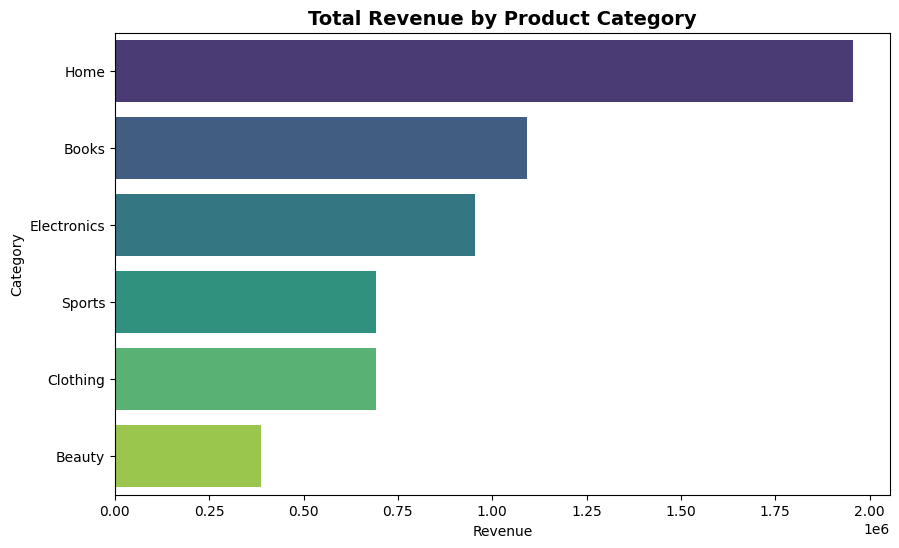

In [ ]:
#category performance
category_perf = df_enriched_sales.groupby('category').agg(
    revenue=('total_amount', 'sum'),
    order_count = ('transaction_id', 'nunique')
).sort_values(by='revenue', ascending=False).reset_index()

#AOV per category
category_perf['avg_order_value'] = category_perf['revenue'] / category_perf['order_count']

#Visualization
plt.figure(figsize=(10, 6))
sns.barplot(data=category_perf, x='revenue', y='category', hue='category', palette='viridis', legend=False)
plt.title('Total Revenue by Product Category',fontsize=14, fontweight='bold')
plt.xlabel('Revenue')
plt.ylabel('Category')
plt.show()

In [ ]:
#Summary table
print("category performance")
display(category_perf.round(2))

category performance


,category,revenue,order_count,avg_order_value
0,Home,1956175.96,5333,366.81
1,Books,1093287.99,6306,173.37
2,Electronics,955397.70,3909,244.41
3,Sports,691892.21,2792,247.81
4,Clothing,691834.74,3907,177.08
5,Beauty,388350.11,1558,249.26


The analysis reveals that the home category is the most performing category. it is more profitable due to its high average order value.
It is suprising that electronics ranked third in revenue behind both home and books.
while many businesses peak during the holiday season, this dataset shows a drop in november and december.
The business should investigate the cause of the decline in sales during last 3 months.
Company can launch holiday gift bundle campaign during that time. ex: bundle one category with another , provide loyaly rewards

In [ ]:
df_enriched_sales.to_csv('df_enriched_sales.csv', index=False)
print("file daved: transactions_enriched.csv")


file daved: transactions_enriched.csv


Executive Summary

Project Overview:
This report summarizes the findings from a comprehensive analysis of customer demographics and transaction history. The goal was to identify customer behavior and sales performance.

Key Insights:
the home category is our most significant reveue driver, generating approximately $1.95M.

While Books category has a lower total revenue, it drives the highest volume with 6306 orders, which suggests that customers may visit frequently for Books but spend more per visit on Home items.

Sales drops significantly during novemebr and december. this is totally contradicts to the standard holiday season revenue expectations, indicating a major issue to fix.

Recommendations:
To address the last 3 months sales drop, it would be ideal to launch cross category bundling, provide loyalty rewards.

Also our analysis identified a large group of At Risk customers(no purchases in 180 days) as well. we can launch a personlized email campaign to resolve that issue.

Data Limitations: the missing ages of some customers needed to guessed by using the median of age of the group. if these missing customers are actually mostly older or mostly younger, our marketing plan might not be perfecly accuarate for those specific groups.